# CODE 3.1: Make Windows

> **Goal:** cut the data into **windows**: the last 60 minutes before a moment, one window every 5 minutes. Then turn every window into the input of each model: a row of summary numbers for Isolation Forest, and the raw readings for the LSTM.
>
> - **Input:**
>   - `data/processed/metropt3.parquet` (notebook 1.1).
>   - `results/time_split.csv` (notebook 1.2): where each part starts.
>   - `data/processed/labels.parquet` (notebook 1.2), only for a check. Only its `split` column is read; the zones stay closed.
>   - The decisions of notebook 2.1: 60-minute windows every 5 minutes, no gaps inside, oil temperature as a change, all 15 signals.
> - **Output:**
>   - `data/processed/windows.parquet`: one row per window, with when it ends, its part (train, validation or test), where it sits in the grid, and its 46 summary numbers.
>   - `data/processed/grid.npz`: all readings on a regular 10-second clock, scaled for the LSTM, plus the scaling numbers.
>
> At the end you should see **ALL CHECKS PASSED**.
>
> **No learning on validation or test.** The only numbers this notebook learns from the data are the scaling numbers, and they come from February. No chart shows a test window.

### Words Used in This Notebook

> - **Window:** the last 60 minutes of readings before a moment. A model judges one window at a time.
> - **Window end:** the moment a window belongs to. The window ending at 11:00 holds the readings from 10:00:10 to 11:00:00.
> - **Grid:** a clock that ticks every 10 seconds, always on the same seconds (00, 10, 20, ...).
> - **Feature:** one summary number of a window, for example the highest motor current in that hour.
> - **Standard deviation (std):** how far the values usually are from their average. Small std: the values stay close together.
> - **Scaling:** from every value of a signal, subtract its February average and divide by its February std. Then every signal sits around 0 with a spread of about 1, whether it was measured in bar, A or °C. Like turning rupiah, dollars and yen into one currency before you compare prices.

## Import Libraries & Variables

### Import Libraries

> - `os`: works with folders and file paths.
> - `numpy`: works with big arrays of numbers. `sliding_window_view` cuts an array into overlapping windows without copying it.
> - `pandas`: works with tables and times.
> - `matplotlib`: draws charts.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

### Variables

#### Folder Paths

> - `ROOT_DIR`: the main project folder (the folder with `requirements.txt`).
> - `PARQUET_FILE`, `SPLIT_FILE`, `LABELS_FILE`: the inputs from notebooks 1.1 and 1.2.
> - `WINDOWS_FILE`, `GRID_FILE`: the two files this notebook saves.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
PARQUET_FILE = os.path.join(PROCESSED_DIR, "metropt3.parquet")
SPLIT_FILE = os.path.join(ROOT_DIR, "results", "time_split.csv")
LABELS_FILE = os.path.join(PROCESSED_DIR, "labels.parquet")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Window Settings

> - `WINDOW_MINUTES`, `STEP_MINUTES`: decided in notebook 2.1.
> - `GRID_SECONDS`: one tick of the grid every 10 seconds, like the readings.
> - `MAX_AGE_SECONDS`: a grid tick takes the latest reading, but only if that reading is at most 30 seconds old. Notebook 1.1 found no step between 30 and 60 seconds: steps are either short or a real gap. So only a real gap leaves ticks without a reading.
> - `WINDOW_STEPS`, `STEP_TICKS`: the same in grid ticks: 360 ticks per window, a new window every 30 ticks.
> - `FIRST_TIME`: the first tick, at the first reading.

In [3]:
WINDOW_MINUTES = 60
STEP_MINUTES = 5
GRID_SECONDS = 10
MAX_AGE_SECONDS = 30
WINDOW_STEPS = WINDOW_MINUTES * 60 // GRID_SECONDS
STEP_TICKS = STEP_MINUTES * 60 // GRID_SECONDS
FIRST_TIME = "2020-02-01T00:00:00"
print(f"{WINDOW_STEPS} ticks per window, a new window every {STEP_TICKS} ticks")

360 ticks per window, a new window every 30 ticks


#### Signals

> - `ANALOG_COLUMNS`, `DIGITAL_COLUMNS`: the 7 numbers and the 8 on/off signals. `SIGNALS` is both, in this order: it is also the order of the 15 rows the LSTM reads.
> - `LEVEL_COLUMNS`: the numbers whose level we keep: all except the oil temperature (decision 3 of notebook 2.1).
> - `OIL_COLUMN`, `PUMP_COLUMN`, `TANK_COLUMN`: the signals with a special job: the oil temperature, the pumping signal, and the tank pressure.
> - `EXAMPLE_END`: one February window to look at, ending at 11:00 on the day of notebook 2.1.

In [4]:
ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
SIGNALS = ANALOG_COLUMNS + DIGITAL_COLUMNS
OIL_COLUMN = "Oil_temperature"
PUMP_COLUMN = "DV_eletric"
TANK_COLUMN = "Reservoirs"
LEVEL_COLUMNS = [column for column in ANALOG_COLUMNS if column != OIL_COLUMN]
EXAMPLE_END = "2020-02-12 11:00:00"

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [5]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Put the Readings on a 10-Second Grid

> The readings come every 9 to 13 seconds, not exactly every 10. The LSTM reads a window step by step, so every step must stand for the same amount of time. `make_grid()` makes a clock that ticks every 10 seconds, and gives every tick the **latest reading** at or before it, like a metronome that always shows the last note it heard.
>
> If the latest reading is older than `max_age_seconds`, the tick gets no reading (`NaN`): the train was switched off. `has_reading` says, for every tick, whether it has one.

In [6]:
def make_grid(times, values, first_time, grid_seconds, max_age_seconds):
    reading_seconds = times.astype("datetime64[s]").astype(np.int64)
    tick_seconds = np.arange(np.datetime64(first_time, "s").astype(np.int64), reading_seconds[-1] + 1, grid_seconds)
    latest = np.searchsorted(reading_seconds, tick_seconds, side="right") - 1
    has_reading = (latest >= 0) & (tick_seconds - reading_seconds[np.maximum(latest, 0)] <= max_age_seconds)
    grid_values = values[np.maximum(latest, 0)].astype(np.float32)
    grid_values[~has_reading] = np.nan
    return tick_seconds.astype("datetime64[s]"), grid_values, has_reading

### Where Can a Window End?

> `window_ends()` lists every possible window end: every 30 ticks (5 minutes), starting at the first tick that has 360 ticks before it. For each end, `complete` says whether all 360 ticks of its window have a reading. It counts the ticks without a reading with a running total, so it does not have to look at every window one by one.

In [7]:
def window_ends(has_reading, window_steps, step_ticks):
    ends = np.arange(window_steps, len(has_reading), step_ticks)
    missing_so_far = np.concatenate([[0], np.cumsum(~has_reading)])
    complete = missing_so_far[ends + 1] - missing_so_far[ends + 1 - window_steps] == 0
    return ends, complete

### All Windows at Once

> `all_windows()` gives an array with one entry per window end: for each window its 15 signals, each with 360 ticks. It is only a different *view* on the grid: no number is copied, so it costs almost no memory, even with tens of thousands of windows.

In [8]:
def all_windows(grid_values, window_steps, step_ticks):
    return sliding_window_view(grid_values, window_steps, axis=0)[1::step_ticks]

### Summary Numbers: Levels

> For every number in `level_columns`: the average (`mean`), the spread (`std`), the lowest (`min`) and the highest (`max`) value in the window.

In [9]:
def level_features(windows, signals, level_columns):
    features = {}
    for column in level_columns:
        values = windows[:, signals.index(column), :]
        features[f"{column}_mean"] = values.mean(axis=1)
        features[f"{column}_std"] = values.std(axis=1)
        features[f"{column}_min"] = values.min(axis=1)
        features[f"{column}_max"] = values.max(axis=1)
    return pd.DataFrame(features)

### Summary Numbers: Oil Temperature as a Change

> Not the level of the oil temperature, but how it moved in the window: how much it changed from the first to the last tick (`change`), how far apart its lowest and highest value are (`range`), and its spread (`std`).

In [10]:
def oil_features(windows, signals, oil_column):
    values = windows[:, signals.index(oil_column), :]
    return pd.DataFrame({f"{oil_column}_change": values[:, -1] - values[:, 0],
                         f"{oil_column}_range": values.max(axis=1) - values.min(axis=1),
                         f"{oil_column}_std": values.std(axis=1)})

### Summary Numbers: On/Off Signals

> For every on/off signal: the share of ticks it is on (`on_share`, from 0 to 1), and how often it switches between 0 and 1 (`switches`).

In [11]:
def switch_features(windows, signals, digital_columns):
    features = {}
    for column in digital_columns:
        values = windows[:, signals.index(column), :]
        features[f"{column}_on_share"] = values.mean(axis=1)
        features[f"{column}_switches"] = np.abs(np.diff(values, axis=1)).sum(axis=1)
    return pd.DataFrame(features)

### Summary Numbers: the "Slow Puncture" Features

> Three numbers about the pump cycles of notebook 2.1:
>
> - `pump_starts`: how often the pumping signal turns from 0 to 1.
> - `drop_bar_per_min`: how fast the tank pressure falls between two ticks that are both *resting*, turned into bar per minute. An air leak should make this bigger.
> - `rise_bar_per_min`: how fast the tank pressure rises between two ticks that are both *pumping*. A leak could make this smaller, because part of the new air escapes.
>
> If a window has no resting or no pumping ticks at all, the speed is set to 0.

In [12]:
def cycle_features(windows, signals, pump_column, tank_column, grid_seconds):
    pumping = windows[:, signals.index(pump_column), :]
    tank = windows[:, signals.index(tank_column), :]
    tank_step = np.diff(tank, axis=1)
    resting_steps = (pumping[:, :-1] == 0) & (pumping[:, 1:] == 0)
    pumping_steps = (pumping[:, :-1] == 1) & (pumping[:, 1:] == 1)
    per_minute = 60 / grid_seconds
    resting_count = resting_steps.sum(axis=1)
    pumping_count = pumping_steps.sum(axis=1)
    drop = np.where(resting_count > 0, -(tank_step * resting_steps).sum(axis=1) / np.maximum(resting_count, 1) * per_minute, 0.0)
    rise = np.where(pumping_count > 0, (tank_step * pumping_steps).sum(axis=1) / np.maximum(pumping_count, 1) * per_minute, 0.0)
    return pd.DataFrame({"pump_starts": (np.diff(pumping, axis=1) == 1).sum(axis=1),
                         "drop_bar_per_min": drop,
                         "rise_bar_per_min": rise})

### One Window for the LSTM

> `lstm_window()` cuts one window out of the scaled grid: the 360 ticks up to and including `end_index`, with all 15 signals. Then it turns the oil temperature into a change: from every tick it subtracts the first tick of the window, so the window always starts at 0 and only the rise or fall during the hour is left.
>
> Notebook 4.2 uses exactly this function to feed the LSTM.

In [13]:
def lstm_window(grid_scaled, end_index, window_steps, oil_index):
    window = grid_scaled[end_index - window_steps + 1:end_index + 1].copy()
    window[:, oil_index] -= window[0, oil_index]
    return window

## What a Window Is

### The Idea

> A model does not look at all seven months at once. Like a security guard who, every 5 minutes, replays the last hour of the camera, a model looks at the **last 60 minutes** and says how normal they are. Five minutes later it looks again, at the newest 60 minutes.
>
> Why like this? It is how the model will work in real use: at every moment it only knows the past, and it gives a new judgment every 5 minutes. And why 60 minutes? Notebook 2.1 showed that a shorter window rarely holds a full pump cycle.

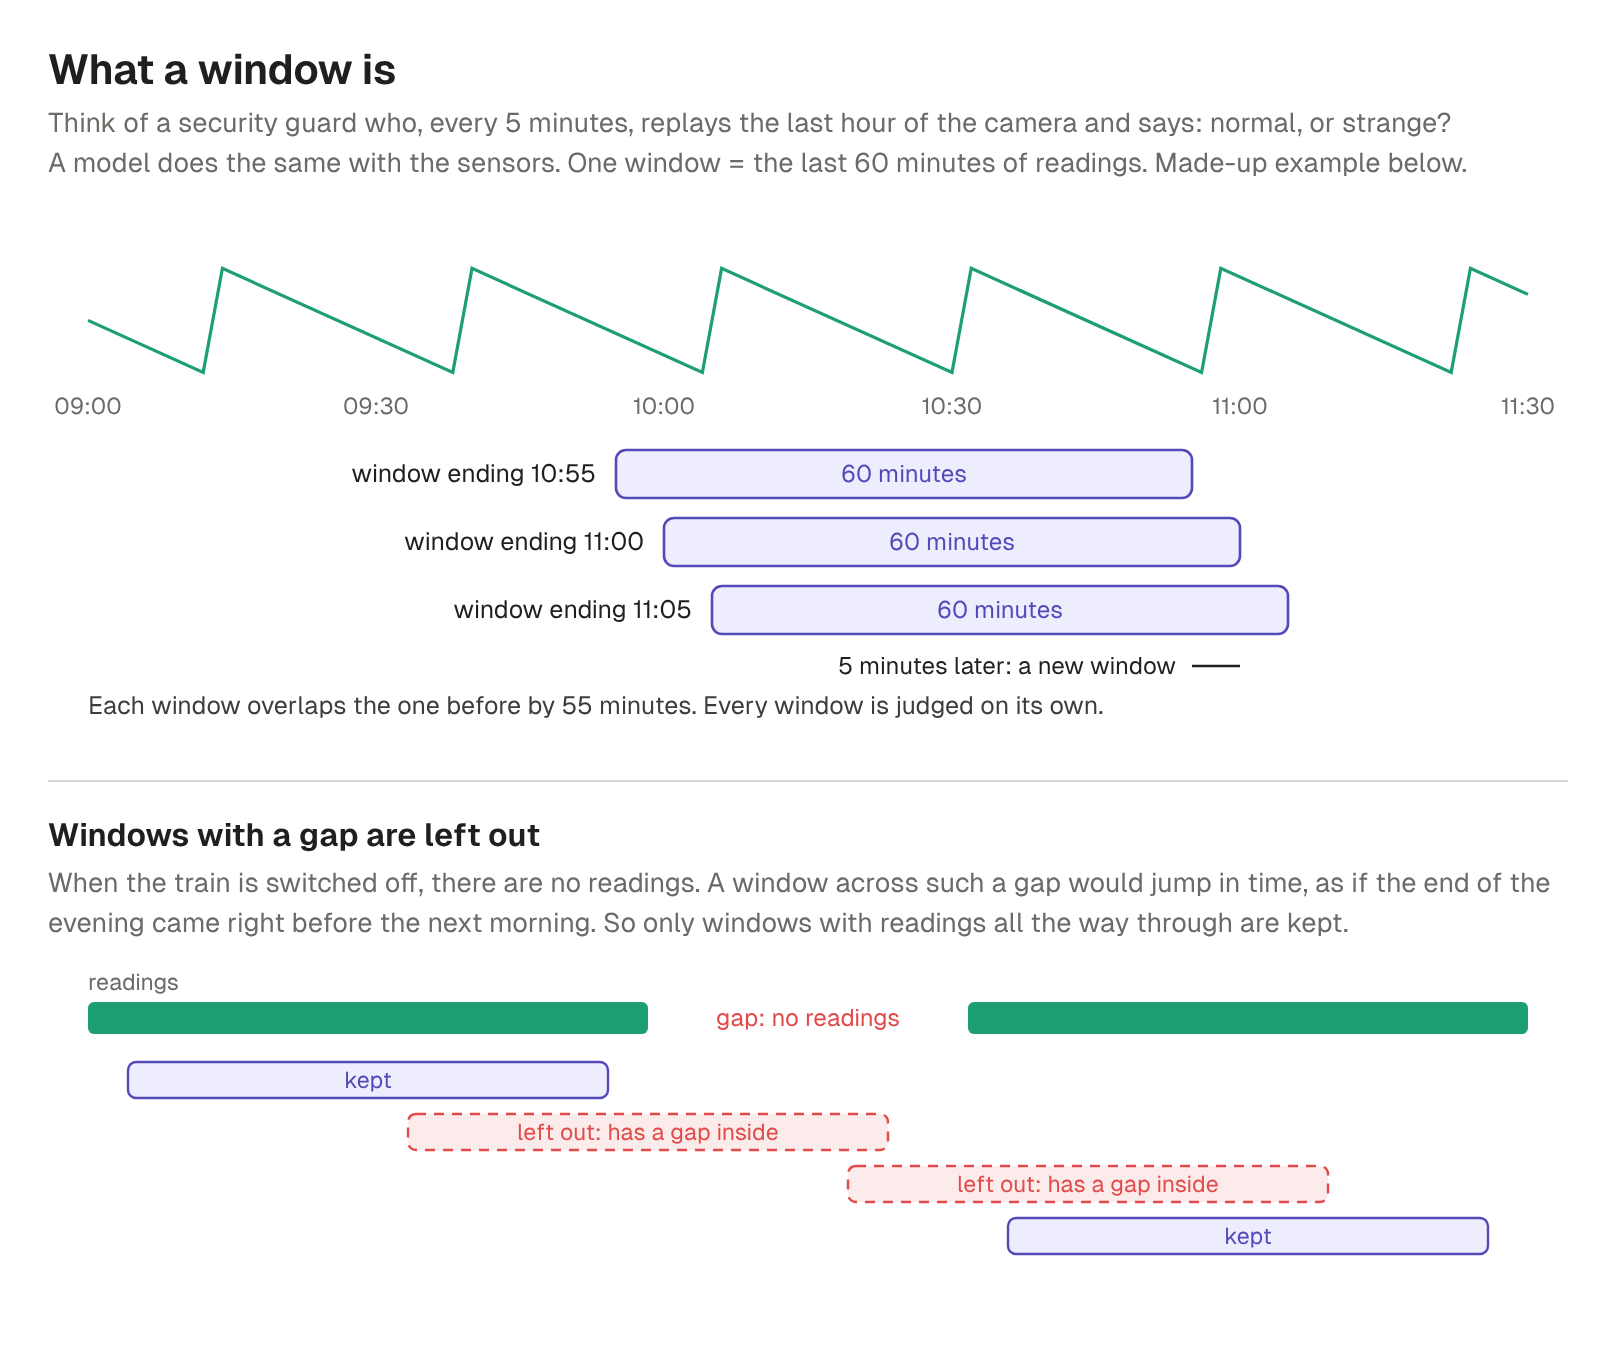

## Step 1: A Regular 10-Second Grid

### Load the Readings and Make the Grid

> All months are loaded, because every window of every month needs its input. Nothing is learned from them here: the grid only moves readings onto the 10-second ticks.

In [14]:
df_sensors = pd.read_parquet(PARQUET_FILE)
grid_times, grid_values, has_reading = make_grid(times=df_sensors["timestamp"].to_numpy(), values=df_sensors[SIGNALS].to_numpy(),
                                                 first_time=FIRST_TIME, grid_seconds=GRID_SECONDS, max_age_seconds=MAX_AGE_SECONDS)
print(f"Readings: {len(df_sensors):,} | grid ticks: {len(grid_times):,} | ticks with a reading: {has_reading.mean() * 100:.1f}%")
print("First tick:", grid_times[0], "| last tick:", grid_times[-1])
print("Grid size:", grid_values.shape, "(ticks, signals)")

Readings: 1,516,948 | grid ticks: 1,841,760 | ticks with a reading: 82.3%
First tick: 2020-02-01T00:00:00 | last tick: 2020-09-01T03:59:50
Grid size: (1841760, 15) (ticks, signals)


> **Check: every gap stops the windows.** For every gap of more than 60 seconds between two readings, at least one tick inside the gap must be without a reading. Then no window can stretch across a gap.

In [15]:
reading_seconds = df_sensors["timestamp"].to_numpy().astype("datetime64[s]").astype(np.int64)
tick_seconds = grid_times.astype(np.int64)
gap_rows = np.flatnonzero(np.diff(reading_seconds) > 60)
first_tick_after = np.searchsorted(tick_seconds, reading_seconds[gap_rows] + MAX_AGE_SECONDS, side="right")
print(f"Gaps of more than 60 seconds: {len(gap_rows)}")
check("every gap leaves at least one tick without a reading",
      ((tick_seconds[first_tick_after] < reading_seconds[gap_rows + 1]) & ~has_reading[first_tick_after]).all())

Gaps of more than 60 seconds: 331
PASS  every gap leaves at least one tick without a reading


## Step 2: Cut the Windows

### Keep Only Complete Windows

> A window is kept when all its 360 ticks have a reading.

In [16]:
ends, complete = window_ends(has_reading=has_reading, window_steps=WINDOW_STEPS, step_ticks=STEP_TICKS)
kept_ends = ends[complete]
print(f"Possible window ends (one every {STEP_MINUTES} minutes): {len(ends):,}")
print(f"Complete windows, kept: {len(kept_ends):,} ({complete.mean() * 100:.1f}%)\n")

tick_ok = sliding_window_view(has_reading, WINDOW_STEPS)[kept_ends - WINDOW_STEPS + 1].all(axis=1)
check(f"every kept window has a reading in all {WINDOW_STEPS} ticks", tick_ok.all())
check("every window ends exactly on a 5-minute mark", (tick_seconds[kept_ends] % (STEP_MINUTES * 60) == 0).all())

Possible window ends (one every 5 minutes): 61,380
Complete windows, kept: 47,491 (77.4%)

PASS  every kept window has a reading in all 360 ticks
PASS  every window ends exactly on a 5-minute mark


### Which Part Is Each Window In?

> A window belongs to the part of its **end**, the moment it is judged. The parts come from `results/time_split.csv`, as in notebook 2.1, so the window that ends at 1 April 00:00 is the first test window.
>
> A validation window that ends early on 1 March still holds some February minutes, and the first test windows hold some March minutes. That is fine: it is only the past, which a model in real use would also have seen. The other way around is not allowed. The checks prove it with `labels.parquet`: no train window holds a reading of a later part, and no validation window holds a test reading. Only the `split` column of `labels.parquet` is read, never the zones: the models must not know where the leaks are.

In [17]:
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
validation_from = pd.Timestamp(split_table.loc["validation", "from"])
test_from = pd.Timestamp(split_table.loc["test", "from"])

df_windows = pd.DataFrame({"end": pd.to_datetime(grid_times[kept_ends]).astype("datetime64[us]"), "end_index": kept_ends})
df_windows["start"] = df_windows["end"] - pd.Timedelta(seconds=(WINDOW_STEPS - 1) * GRID_SECONDS)
df_windows["split"] = pd.Categorical(np.select([df_windows["end"] < validation_from, df_windows["end"] < test_from], ["train", "validation"], default="test"),
                                     categories=["train", "validation", "test"])
display(df_windows.groupby("split", observed=True).agg(windows=("end", "size"), first_end=("end", "min"), last_end=("end", "max")))

labels = pd.read_parquet(LABELS_FILE, columns=["timestamp", "split"])
first_reading = labels.groupby("split", observed=True)["timestamp"].min()
print("Columns read from labels.parquet:", list(labels.columns))
print("First reading of each part:", {name: str(time) for name, time in first_reading.items()}, "\n")
check("no train window holds a reading of validation or test", (df_windows.loc[df_windows["split"] == "train", "end"] < first_reading["validation"]).all())
check("no validation window holds a reading of test", (df_windows.loc[df_windows["split"] == "validation", "end"] < first_reading["test"]).all())
check("every train window starts in February", (df_windows.loc[df_windows["split"] == "train", "start"] >= pd.Timestamp(FIRST_TIME)).all())

,windows,first_end,last_end
split,,,
train,6790,2020-02-01 01:00:00,2020-02-28 23:55:00
validation,7194,2020-03-01 05:00:00,2020-03-31 23:55:00
test,33507,2020-04-01 00:00:00,2020-09-01 03:55:00


Columns read from labels.parquet: ['timestamp', 'split']
First reading of each part: {'train': '2020-02-01 00:00:00', 'validation': '2020-03-01 04:00:09', 'test': '2020-04-01 00:00:09'} 

PASS  no train window holds a reading of validation or test
PASS  no validation window holds a reading of test
PASS  every train window starts in February


## Step 3: The Summary for Isolation Forest

### What Each Model Gets

> The same window is given to the two models in two forms:
>
> - **Isolation Forest** gets a summary card: one row of 46 numbers about the hour.
> - **The LSTM** gets the whole recording: 360 ticks of all 15 signals, and reads it step by step.

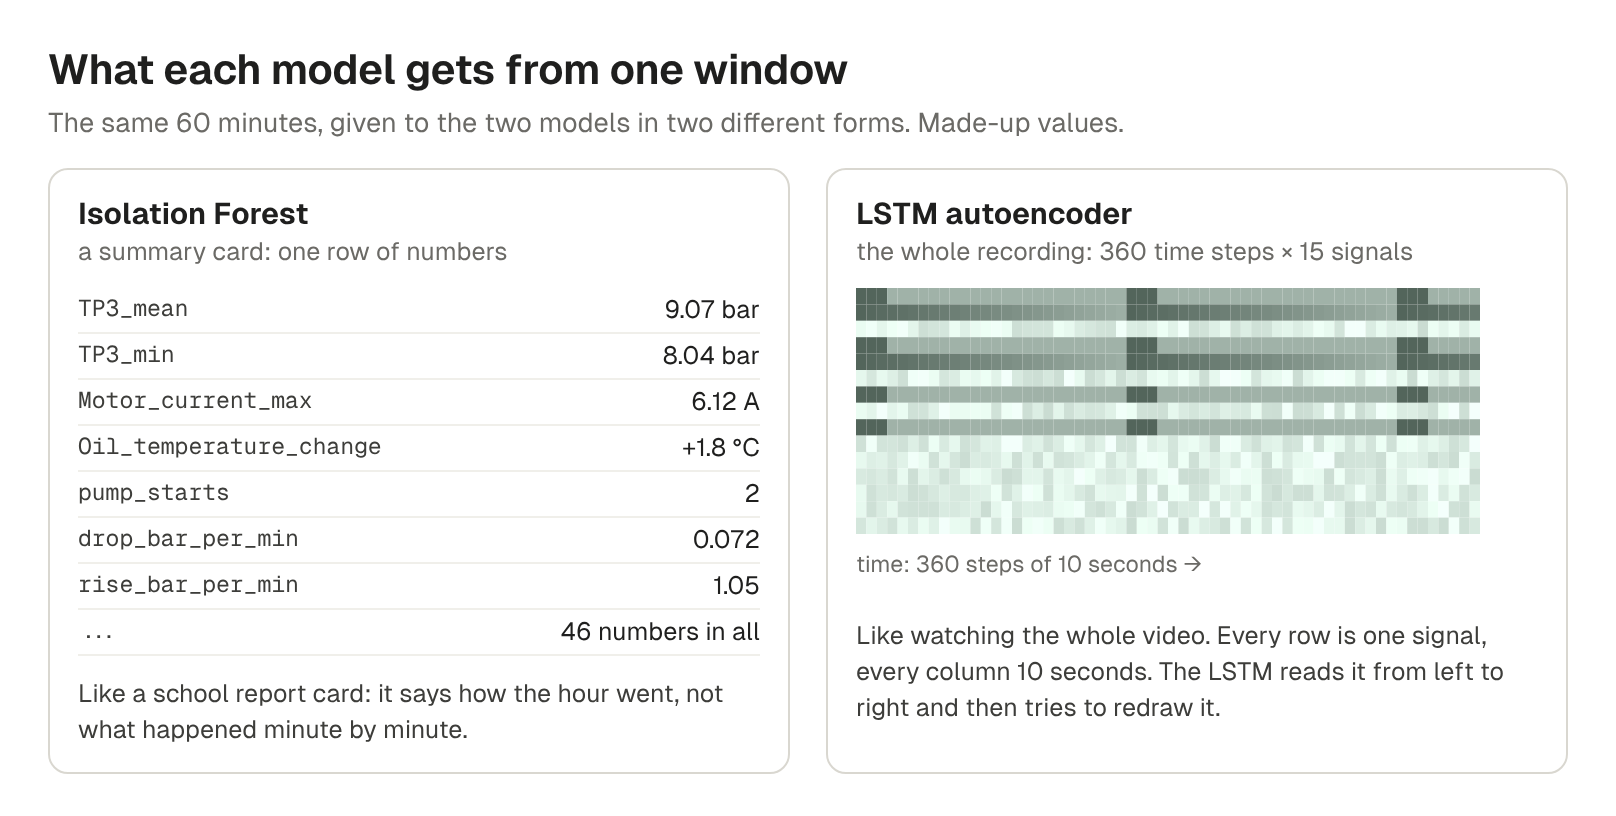

### Compute the 46 Numbers

> The four functions above are run on all windows at once. The summary uses the **unscaled** values, in bar, A and °C: Isolation Forest does not need scaling, because it only asks "is this value above or below a split point?". The real units also make the explanations of notebook 5.3 easier to read.

In [18]:
windows = all_windows(grid_values=grid_values, window_steps=WINDOW_STEPS, step_ticks=STEP_TICKS)
print("Windows in the view:", windows.shape, "(window ends, signals, ticks)")

features = pd.concat([level_features(windows=windows, signals=SIGNALS, level_columns=LEVEL_COLUMNS),
                      oil_features(windows=windows, signals=SIGNALS, oil_column=OIL_COLUMN),
                      switch_features(windows=windows, signals=SIGNALS, digital_columns=DIGITAL_COLUMNS),
                      cycle_features(windows=windows, signals=SIGNALS, pump_column=PUMP_COLUMN, tank_column=TANK_COLUMN, grid_seconds=GRID_SECONDS)],
                     axis=1)
features = features[complete].reset_index(drop=True).astype("float32")
FEATURE_COLUMNS = list(features.columns)
df_windows = pd.concat([df_windows, features], axis=1)

print(f"Features per window: {len(FEATURE_COLUMNS)}")
print(f"  levels: {len(LEVEL_COLUMNS) * 4} | oil temperature: 3 | on/off signals: {len(DIGITAL_COLUMNS) * 2} | pump cycles: 3\n")
check("every window has 46 numbers, none missing and none infinite",
      len(FEATURE_COLUMNS) == 46 and np.isfinite(df_windows[FEATURE_COLUMNS].to_numpy()).all())

Windows in the view: (61380, 15, 360) (window ends, signals, ticks)
Features per window: 46
  levels: 24 | oil temperature: 3 | on/off signals: 16 | pump cycles: 3

PASS  every window has 46 numbers, none missing and none infinite


### The Summary of One February Window

> The window that ends at `EXAMPLE_END`, the hour that notebook 2.1 showed up close.

In [19]:
example = df_windows[df_windows["end"] == pd.Timestamp(EXAMPLE_END)]
print("Window:", example["start"].iloc[0], "to", example["end"].iloc[0], "| part:", example["split"].iloc[0])
display(example[FEATURE_COLUMNS].T.rename(columns={example.index[0]: "value"}).round(3))

Window: 2020-02-12 10:00:10 to 2020-02-12 11:00:00 | part: train


,value
TP2_mean,0.504
TP2_std,2.134
TP2_min,-0.024
TP2_max,10.352
TP3_mean,8.811
TP3_std,0.502
TP3_min,8.036
TP3_max,10.092
H1_mean,8.269
H1_std,2.114


> **How to read it:** in this hour the compressor started pumping twice (`pump_starts`), the tank pressure fell by less than a tenth of a bar per minute while resting (`drop_bar_per_min`), and it stayed between about 8 and 10 bar (`Reservoirs_min`, `Reservoirs_max`). These are the numbers of the chart "One Hour Up Close" in notebook 2.1, written as one row.

## Step 4: The Input for the LSTM

### Scaling Numbers from February

> The LSTM learns best when all signals are about the same size. Without scaling, `Oil_temperature` (around 56) would shout over `DV_pressure` (around 0). So each of the 7 numbers is scaled with the average and the std of **February** ticks only. The 8 on/off signals are already 0 or 1 and stay as they are.
>
> Why only February: the scaling numbers are learned from data. If March or the test months were in them, a little of their information would sneak into the model: data leakage.

In [20]:
validation_from_tick = np.datetime64(validation_from)
train_ticks = has_reading & (grid_times < validation_from_tick)
train_values = grid_values[train_ticks][:, :len(ANALOG_COLUMNS)].astype(np.float64)
scale_mean = train_values.mean(axis=0)
scale_std = train_values.std(axis=0)

print(f"Ticks used for the scaling: {train_ticks.sum():,}, the last one at {grid_times[train_ticks].max()}")
display(pd.DataFrame({"average": scale_mean, "std": scale_std}, index=ANALOG_COLUMNS).round(4))

Ticks used for the scaling: 213,044, the last one at 2020-02-28T23:57:30


,average,std
TP2,0.5375,2.1972
TP3,8.9621,0.5521
H1,8.3983,2.1987
DV_pressure,-0.0156,0.1052
Reservoirs,8.9641,0.5515
Oil_temperature,56.3095,3.4127
Motor_current,1.2447,1.9618


In [21]:
grid_scaled = grid_values.copy()
grid_scaled[:, :len(ANALOG_COLUMNS)] = (grid_values[:, :len(ANALOG_COLUMNS)] - scale_mean) / scale_std

scaled_train = grid_scaled[train_ticks][:, :len(ANALOG_COLUMNS)].astype(np.float64)
print("Average after scaling, February ticks:", (np.round(scaled_train.mean(axis=0), 3) + 0.0).tolist())
print("Std after scaling, February ticks:    ", (np.round(scaled_train.std(axis=0), 3) + 0.0).tolist(), "\n")
check("the scaling numbers come only from February ticks", grid_times[train_ticks].max() < validation_from_tick)
check("after scaling, every number has average 0 and std 1 in February",
      np.allclose(scaled_train.mean(axis=0), 0, atol=1e-3) and np.allclose(scaled_train.std(axis=0), 1, atol=1e-3))
check("the on/off signals are unchanged", np.array_equal(grid_scaled[:, len(ANALOG_COLUMNS):], grid_values[:, len(ANALOG_COLUMNS):], equal_nan=True))

Average after scaling, February ticks: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Std after scaling, February ticks:     [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0] 

PASS  the scaling numbers come only from February ticks
PASS  after scaling, every number has average 0 and std 1 in February
PASS  the on/off signals are unchanged


### One February Window as the LSTM Sees It

> The same example window, cut with `lstm_window()`. On top, the tank pressure in bar, so you can recognize the hour. Below, all 15 rows the LSTM reads: dark is low, light is high, after scaling. The `Oil_temperature` row now starts at 0 and only shows its change.

LSTM input of one window: (360, 15) (ticks, signals)
Oil temperature row: first value 0.00, last value 0.18


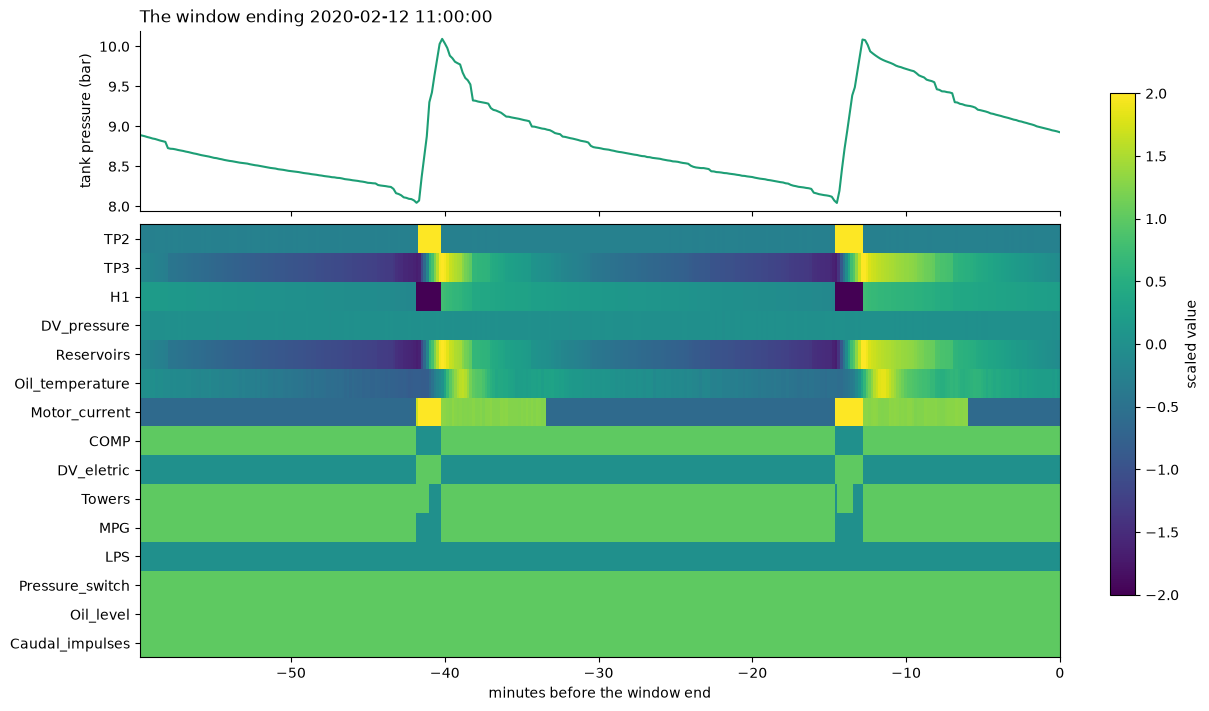

In [22]:
example_index = int(example["end_index"].iloc[0])
example_input = lstm_window(grid_scaled=grid_scaled, end_index=example_index, window_steps=WINDOW_STEPS, oil_index=SIGNALS.index(OIL_COLUMN))
minutes = np.arange(-WINDOW_STEPS + 1, 1) * GRID_SECONDS / 60
print("LSTM input of one window:", example_input.shape, "(ticks, signals)")
print(f"Oil temperature row: first value {example_input[0, SIGNALS.index(OIL_COLUMN)]:.2f}, last value {example_input[-1, SIGNALS.index(OIL_COLUMN)]:.2f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [1, 2.4]}, sharex=True, layout="constrained")
axes[0].plot(minutes, grid_values[example_index - WINDOW_STEPS + 1:example_index + 1, SIGNALS.index(TANK_COLUMN)], color="#1D9E75")
axes[0].set_ylabel("tank pressure (bar)")
axes[0].set_title(f"The window ending {EXAMPLE_END}", loc="left")
for side in ["top", "right"]:
    axes[0].spines[side].set_visible(False)
image = axes[1].imshow(example_input.T, aspect="auto", cmap="viridis", interpolation="nearest",
                       extent=[minutes[0], minutes[-1], len(SIGNALS) - 0.5, -0.5], vmin=-2, vmax=2)
axes[1].set_yticks(range(len(SIGNALS)), SIGNALS)
axes[1].set_xlabel("minutes before the window end")
fig.colorbar(image, ax=axes, shrink=0.8, label="scaled value")
plt.show()

> **What we see:** the two pump phases of the hour are two short bright stripes in `TP2` and `Motor_current`, and two dark stripes in `H1`, which does the opposite. After each pump phase, `Motor_current` stays a bit brighter for a few minutes: the motor keeps turning without pumping. The saw-tooth of the tank pressure becomes a fade in `TP3` and `Reservoirs`: bright right after pumping, darker and darker until the next pump. The `Oil_temperature` row starts at 0 and gets brighter after each pump phase, when the oil warms up. The on/off rows have only two colors: blue-green for 0 and green for 1.
>
> This picture, 360 columns wide and 15 rows high, is exactly what the LSTM will learn to redraw.

## Save

### Save the Windows and the Grid

> - `windows.parquet`: one row per kept window. `end_index` says where the window ends in the grid, so notebook 4.2 can cut it out with `lstm_window()`.
> - `grid.npz`: the scaled grid, the tick times, which ticks have a reading, and the scaling numbers. Ticks without a reading stay `NaN`; no kept window touches them.
>
> Both files are read back and compared.

In [23]:
os.makedirs(PROCESSED_DIR, exist_ok=True)
df_windows = df_windows[["end", "start", "end_index", "split"] + FEATURE_COLUMNS]
df_windows.to_parquet(WINDOWS_FILE, index=False)
np.savez(GRID_FILE, values=grid_scaled, has_reading=has_reading, tick_seconds=tick_seconds,
         signals=np.array(SIGNALS), scaled_columns=np.array(ANALOG_COLUMNS), scale_mean=scale_mean, scale_std=scale_std)

for path in [WINDOWS_FILE, GRID_FILE]:
    print(f"Saved: {os.path.relpath(path, ROOT_DIR)} ({os.path.getsize(path) / 1024**2:.1f} MB)")

Saved: data\processed\windows.parquet (5.2 MB)
Saved: data\processed\grid.npz (121.2 MB)


In [24]:
windows_back = pd.read_parquet(WINDOWS_FILE)
with np.load(GRID_FILE) as saved:
    grid_back = {name: saved[name] for name in saved.files}

check("windows.parquet has exactly the table in memory", windows_back.equals(df_windows))
check("grid.npz has exactly the scaled grid in memory", np.array_equal(grid_back["values"], grid_scaled, equal_nan=True))
check("grid.npz has the February scaling numbers", np.array_equal(grid_back["scale_mean"], scale_mean) and np.array_equal(grid_back["scale_std"], scale_std))
check("the example window comes back the same from the saved grid",
      np.array_equal(lstm_window(grid_scaled=grid_back["values"], end_index=example_index, window_steps=WINDOW_STEPS, oil_index=SIGNALS.index(OIL_COLUMN)), example_input))

PASS  windows.parquet has exactly the table in memory
PASS  grid.npz has exactly the scaled grid in memory
PASS  grid.npz has the February scaling numbers
PASS  the example window comes back the same from the saved grid


## Result

### Final Result

> If every check passed, every window is complete, sits in the right part, and has both inputs ready. If a check failed, its name is printed.

In [25]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (14 checks)


## Summary

> - The readings are put on a **10-second grid**. A tick without a reading of the last 30 seconds marks a gap.
> - A **window** is the last 60 minutes before a moment, one every 5 minutes. Only **complete** windows are kept, so no window crosses a gap.
> - Every window belongs to the part of its end. No train window holds a minute of March.
> - **Isolation Forest** gets 46 summary numbers per window, in real units: levels of 6 numbers, the oil temperature as a change, the on/off signals, and the 3 "slow puncture" features.
> - **The LSTM** gets the window itself: 360 ticks × 15 signals, scaled with February numbers only, with the oil temperature as a change.
> - Saved: `data/processed/windows.parquet` and `data/processed/grid.npz`.
>
> **Next:** `notebooks/3_preprocessing/3.2_check_windows.ipynb`